# Telco Customer Churn: calibrated, audited model pipeline

This revision answers eight review points on the previous notebook.

| # | Point | What this notebook does |
|---|---|---|
| 1 | Scores inflated by `scale_pos_weight` | Final pipeline wrapped in `CalibratedClassifierCV`, fitted on training data only; method picked by out-of-fold Brier score; reliability curve and Brier score on the test set |
| 2 | Threshold from costs | Threshold = offer cost / (success rate x customer value) on calibrated scores when you supply those numbers; **otherwise a labelled placeholder** (F1-optimal on calibrated out-of-fold scores) |
| 3 | `TotalCharges` redundant, blanks wrongly median-filled | Ablation: blanks filled with 0, or the column dropped; the simplest variant within 0.001 AUC of the best is used |
| 4 | Noisy single test split | Bootstrap confidence intervals, repeated CV over several seeds, and a `Contract` + `tenure` baseline |
| 5 | Optimistic model selection | Selection by nested cross-validation |
| 6 | Subgroup behaviour | Recall, precision and flag rate by gender, SeniorCitizen, Partner, Dependents; `gender` dropped as an input if it adds nothing |
| 7 | Unsafe serving | `churn_serving.py` validates columns, types and ranges; library versions are saved in the meta file |
| 8 | Local explanations | SHAP for individual predictions, mapped back to raw columns, with an additivity test |

The test set is used only after every choice is made.

In [1]:
import json, sys, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, average_precision_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
SEED = 42
DATA = Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# ---- Business numbers for the threshold (point 2). Leave as None until you have real figures. ----
OFFER_COST = None          # cost of one retention offer, in money
CUSTOMER_VALUE = None      # value kept if a would-be churner stays (e.g. remaining lifetime margin)
SUCCESS_RATE = None        # share of would-be churners an offer actually keeps

CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=7)
OUTER = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

In [2]:
df = pd.read_csv(DATA).drop(columns=['customerID'])
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank = df['TotalCharges'].isna()
print('blank TotalCharges:', int(blank.sum()), '| their tenure values:', sorted(df.loc[blank, 'tenure'].unique()))
print('corr(TotalCharges, tenure*MonthlyCharges) = %.4f' % df['TotalCharges'].corr(df['tenure'] * df['MonthlyCharges']))
y = df['Churn'].map({'Yes': 1, 'No': 0}); assert y.notna().all()
X = df.drop(columns=['Churn'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print('train', X_train.shape, 'test', X_test.shape, '| churn rate %.3f' % y.mean())

def make_prep(Xref, tc_mode, scale=True):
    num = [c for c in Xref.select_dtypes(include='number').columns if c != 'TotalCharges']
    cat = Xref.select_dtypes(exclude='number').columns.tolist()
    sc = [('sc', StandardScaler())] if scale else []
    parts = [('num', Pipeline([('imp', SimpleImputer(strategy='median'))] + sc), num)]
    if 'TotalCharges' in Xref.columns:
        fill = SimpleImputer(strategy='constant', fill_value=0.0) if tc_mode == 'zero' else SimpleImputer(strategy='median')
        parts.append(('tc', Pipeline([('imp', fill)] + sc), ['TotalCharges']))
    parts.append(('cat', OneHotEncoder(handle_unknown='ignore'), cat))
    return ColumnTransformer(parts)

def make_pipe(model, Xref, tc_mode, scale=True):
    return Pipeline([('prep', make_prep(Xref, tc_mode, scale)), ('model', model)])

blank TotalCharges: 11 | their tenure values: [np.int64(0)]
corr(TotalCharges, tenure*MonthlyCharges) = 0.9996
train (5634, 19) test (1409, 19) | churn rate 0.265


In [3]:
# Point 3 and 6: feature ablation with fixed, untuned models, repeated 5x2 CV on the TRAINING set.
variants = {                               # ordered simplest first
    'D: drop TotalCharges + gender': (['TotalCharges', 'gender'], 'drop'),
    'C: drop TotalCharges':          (['TotalCharges'], 'drop'),
    'B: TotalCharges blanks = 0':    ([], 'zero'),
    'A: TotalCharges blanks = median (previous)': ([], 'median'),
}
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=11)
rows = {}
for name, (drop, mode) in variants.items():
    Xv = X_train.drop(columns=drop)
    lr = make_pipe(LogisticRegression(max_iter=5000, C=0.1, class_weight='balanced'), Xv, mode)
    xg = make_pipe(XGBClassifier(n_estimators=250, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.7,
                                 tree_method='hist', random_state=SEED, n_jobs=2), Xv, mode, scale=False)
    rows[name] = {'logreg_auc': cross_val_score(lr, Xv, y_train, cv=RCV, scoring='roc_auc').mean(),
                  'xgb_auc': cross_val_score(xg, Xv, y_train, cv=RCV, scoring='roc_auc').mean()}
abl = pd.DataFrame(rows).T; abl['mean_auc'] = abl.mean(axis=1)
display(abl.round(4))
best_auc = abl['mean_auc'].max()
chosen = next(n for n in variants if abl.loc[n, 'mean_auc'] >= best_auc - 0.001)   # simplest within 0.001 of best
DROP, TC_MODE = variants[chosen]
print('Chosen feature set ->', chosen)
X_train_f, X_test_f = X_train.drop(columns=DROP), X_test.drop(columns=DROP)

,logreg_auc,xgb_auc,mean_auc
D: drop TotalCharges + gender,0.8445,0.8490,0.8468
C: drop TotalCharges,0.8442,0.8486,0.8464
B: TotalCharges blanks = 0,0.8448,0.8495,0.8471
A: TotalCharges blanks = median (previous),0.8448,0.8497,0.8472


Chosen feature set -> D: drop TotalCharges + gender


In [4]:
# Candidate models. make_searches(cv) is reused for the final fit (5-fold) and inside nested CV (3-fold inner).
def make_searches(cv, n_jobs=1):
    Xr = X_train_f
    return {
      'logreg': GridSearchCV(make_pipe(LogisticRegression(max_iter=5000, class_weight='balanced'), Xr, TC_MODE),
                             {'model__C': np.logspace(-3, 1, 13)}, scoring='roc_auc', cv=cv, n_jobs=n_jobs),
      'random_forest': RandomizedSearchCV(
          make_pipe(RandomForestClassifier(random_state=SEED, n_jobs=2, class_weight='balanced_subsample'), Xr, TC_MODE, scale=False),
          {'model__n_estimators': [200, 300], 'model__max_depth': [4, 6, 8, None], 'model__min_samples_leaf': [1, 3, 5, 10, 20],
           'model__max_features': ['sqrt', 0.3, 0.5]}, n_iter=8, scoring='roc_auc', cv=cv, random_state=SEED, n_jobs=1),
      'xgboost': RandomizedSearchCV(
          make_pipe(XGBClassifier(objective='binary:logistic', eval_metric='logloss', tree_method='hist', random_state=SEED, n_jobs=2), Xr, TC_MODE, scale=False),
          {'model__n_estimators': [150, 250, 400], 'model__learning_rate': [0.01, 0.02, 0.03, 0.05, 0.1],
           'model__max_depth': [2, 3, 4, 5, 6], 'model__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
           'model__colsample_bytree': [0.5, 0.7, 0.9, 1.0], 'model__min_child_weight': [1, 3, 5, 10],
           'model__gamma': [0, 0.1, 0.3, 1.0], 'model__reg_lambda': [1, 3, 10, 30],
           'model__scale_pos_weight': [1.0, 1.66, 2.76]}, n_iter=25, scoring='roc_auc', cv=cv, random_state=SEED, n_jobs=1),
      'lightgbm': RandomizedSearchCV(
          make_pipe(LGBMClassifier(random_state=SEED, n_jobs=2, verbose=-1, deterministic=True, force_row_wise=True), Xr, TC_MODE, scale=False),
          {'model__n_estimators': [150, 250, 400], 'model__learning_rate': [0.02, 0.03, 0.05], 'model__num_leaves': [4, 8, 15, 31],
           'model__min_child_samples': [10, 20, 40, 80], 'model__subsample': [0.6, 0.8, 1.0], 'model__subsample_freq': [1],
           'model__colsample_bytree': [0.5, 0.7, 0.9], 'model__reg_lambda': [0, 1, 5, 20],
           'model__scale_pos_weight': [1.0, 1.66, 2.76]}, n_iter=15, scoring='roc_auc', cv=cv, random_state=SEED, n_jobs=1),
    }

def make_baseline():
    # Deliberately simple reference: Contract + tenure only.
    prep = ColumnTransformer([('tenure', StandardScaler(), ['tenure']), ('contract', OneHotEncoder(handle_unknown='ignore'), ['Contract'])])
    return Pipeline([('prep', prep), ('model', LogisticRegression(max_iter=5000))])

searches = make_searches(CV5, n_jobs=2)
for name, s in searches.items():
    s.fit(X_train_f, y_train)
    print(f'{name:14s} 5-fold search best AUC = {s.best_score_:.4f}')

logreg         5-fold search best AUC = 0.8451


random_forest  5-fold search best AUC = 0.8469


xgboost        5-fold search best AUC = 0.8504


lightgbm       5-fold search best AUC = 0.8501


In [5]:
# Point 5: nested CV. The whole search (inner 3-fold) is repeated inside each of 5 outer folds, so outer scores never
# come from folds the search tuned on. Used for the model comparison and selection.
nested = {}
for name in searches:
    sc = cross_val_score(make_searches(CV3)[name], X_train_f, y_train, cv=OUTER, scoring='roc_auc', n_jobs=1)
    nested[name] = sc
nested['baseline (Contract + tenure)'] = cross_val_score(make_baseline(), X_train, y_train, cv=OUTER, scoring='roc_auc')
nested_df = pd.DataFrame({k: {'nested_auc_mean': v.mean(), 'nested_auc_sd': v.std(ddof=1)} for k, v in nested.items()}).T.sort_values('nested_auc_mean', ascending=False)
display(nested_df.round(4))
fam = nested_df.drop(index='baseline (Contract + tenure)')
tied = fam.index[fam['nested_auc_mean'] >= fam['nested_auc_mean'].max() - 0.001]      # differences below 0.001 are noise (outer-fold sd is ~0.017)
best_name = 'xgboost' if 'xgboost' in tied else fam.index[0]                          # on a tie prefer XGBoost, so SHAP explains the model that is served
print('Families within 0.001 nested AUC of the best:', list(tied))
final_pipe = searches[best_name].best_estimator_
print('Selected by nested CV:', best_name, '| params:', searches[best_name].best_params_)

,nested_auc_mean,nested_auc_sd
lightgbm,0.8502,0.0170
xgboost,0.8496,0.0172
random_forest,0.8462,0.0171
logreg,0.8437,0.0182
baseline (Contract + tenure),0.7846,0.0087


Families within 0.001 nested AUC of the best: ['lightgbm', 'xgboost']
Selected by nested CV: xgboost | params: {'model__subsample': 0.9, 'model__scale_pos_weight': 1.66, 'model__reg_lambda': 30, 'model__n_estimators': 250, 'model__min_child_weight': 1, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__gamma': 0.3, 'model__colsample_bytree': 1.0}


In [6]:
# Point 4: repeated CV over several seeds (5 folds x 5 repeats) on the training set, final settings vs baseline.
# Note: the final model's hyperparameters were tuned on these rows, so its figure is mildly optimistic; the nested table above is the fair one.
RCV5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=2024)
rep = {'baseline (Contract + tenure)': cross_val_score(make_baseline(), X_train, y_train, cv=RCV5, scoring='roc_auc'),
       best_name + ' (tuned)': cross_val_score(clone(final_pipe), X_train_f, y_train, cv=RCV5, scoring='roc_auc')}
rep_df = pd.DataFrame({k: {'mean_auc': v.mean(), 'sd': v.std(ddof=1), 'n_scores': len(v)} for k, v in rep.items()}).T
display(rep_df.round(4))
gain = rep[best_name + ' (tuned)'] - rep['baseline (Contract + tenure)']
print('AUC gain over the simple baseline: %.4f (paired, sd %.4f) -> this is what the extra complexity buys' % (gain.mean(), gain.std(ddof=1)))

,mean_auc,sd,n_scores
baseline (Contract + tenure),0.7842,0.0115,25.0
xgboost (tuned),0.8502,0.0108,25.0


AUC gain over the simple baseline: 0.0660 (paired, sd 0.0092) -> this is what the extra complexity buys


In [7]:
# Point 1: calibration. Method (isotonic vs sigmoid) chosen on out-of-fold Brier score of TRAIN data only.
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
oof_cal, oof_brier = {}, {}
for m in ['isotonic', 'sigmoid']:
    est = CalibratedClassifierCV(clone(final_pipe), method=m, cv=inner, ensemble=True)
    oof_cal[m] = cross_val_predict(est, X_train_f, y_train, cv=CV5, method='predict_proba')[:, 1]
    oof_brier[m] = brier_score_loss(y_train, oof_cal[m])
oof_raw = cross_val_predict(clone(final_pipe), X_train_f, y_train, cv=CV5, method='predict_proba')[:, 1]
print('OOF Brier  uncalibrated: %.4f | isotonic: %.4f | sigmoid: %.4f' % (brier_score_loss(y_train, oof_raw), oof_brier['isotonic'], oof_brier['sigmoid']))
CAL_METHOD = min(oof_brier, key=oof_brier.get)
cal_model = CalibratedClassifierCV(clone(final_pipe), method=CAL_METHOD, cv=inner, ensemble=True).fit(X_train_f, y_train)   # training data only
p_oof = oof_cal[CAL_METHOD]
print('Calibration method:', CAL_METHOD)

OOF Brier  uncalibrated: 0.1401 | isotonic: 0.1331 | sigmoid: 0.1340


Calibration method: isotonic


In [8]:
# Point 2: threshold, on calibrated scores.
grid = np.arange(0.02, 0.951, 0.005)
if None not in (OFFER_COST, CUSTOMER_VALUE, SUCCESS_RATE):
    threshold = float(OFFER_COST / (SUCCESS_RATE * CUSTOMER_VALUE))   # treat when p * success * value >= offer cost
    threshold_source = 'expected_value: offer_cost / (success_rate * customer_value)'
    threshold_note = 'Derived from the business numbers supplied in the config cell.'
else:
    f1s = np.array([f1_score(y_train, p_oof >= t) for t in grid])
    threshold = float(grid[int(np.argmax(f1s))])
    threshold_source = 'placeholder_f1_optimal_on_calibrated_oof'
    threshold_note = ('PLACEHOLDER. No offer cost, customer value or success rate was supplied. F1 weighs a missed churner and a wasted offer equally; '
                      'replace with offer_cost / (success_rate * customer_value) once real numbers exist.')
print('threshold = %.3f  [%s]' % (threshold, threshold_source))
# Illustration only (made-up numbers, NOT used anywhere): offer 20, value 800, success 30% -> threshold %.3f
print('Illustration with made-up numbers (not used): offer 20, value 800, success 30%% -> threshold %.3f' % (20 / (0.3 * 800)))

threshold = 0.340  [placeholder_f1_optimal_on_calibrated_oof]
Illustration with made-up numbers (not used): offer 20, value 800, success 30% -> threshold 0.083


In [9]:
# Test-set evaluation with bootstrap confidence intervals (2,000 resamples), calibrated scores.
p_raw_test = final_pipe.predict_proba(X_test_f)[:, 1]
p_test = cal_model.predict_proba(X_test_f)[:, 1]
base_model = make_baseline().fit(X_train, y_train)
p_base = base_model.predict_proba(X_test)[:, 1]
yt = y_test.values

def point(p, t, yv=yt):
    pred = (p >= t).astype(int)
    return {'roc_auc': roc_auc_score(yv, p), 'brier': brier_score_loss(yv, p), 'precision': precision_score(yv, pred, zero_division=0),
            'recall': recall_score(yv, pred), 'f1': f1_score(yv, pred), 'accuracy': accuracy_score(yv, pred), 'flag_rate': pred.mean()}

pt = point(p_test, threshold)
rng = np.random.default_rng(SEED)
B = 2000
idx = rng.integers(0, len(yt), size=(B, len(yt)))
boot = pd.DataFrame([point(p_test[i], threshold, yt[i]) for i in idx])
auc_gain = np.array([roc_auc_score(yt[i], p_test[i]) - roc_auc_score(yt[i], p_base[i]) for i in idx])
ci = {k: [float(boot[k].quantile(0.025)), float(boot[k].quantile(0.975))] for k in boot}
res = pd.DataFrame({'estimate': pt, 'ci_low': {k: v[0] for k, v in ci.items()}, 'ci_high': {k: v[1] for k, v in ci.items()}})
display(res.round(4))
print('Baseline (Contract + tenure) test AUC = %.4f | model - baseline AUC = %.4f, 95%% CI [%.4f, %.4f]' % (
      roc_auc_score(yt, p_base), pt['roc_auc'] - roc_auc_score(yt, p_base), np.quantile(auc_gain, .025), np.quantile(auc_gain, .975)))
print('Confusion matrix [[TN FP] [FN TP]]:'); print(confusion_matrix(yt, (p_test >= threshold).astype(int)))

,estimate,ci_low,ci_high
roc_auc,0.8472,0.8247,0.8680
brier,0.1350,0.1248,0.1456
precision,0.5664,0.5205,0.6093
recall,0.7299,0.6830,0.7751
f1,0.6379,0.5978,0.6744
accuracy,0.7800,0.7580,0.8006
flag_rate,0.3421,0.3165,0.3683


Baseline (Contract + tenure) test AUC = 0.7983 | model - baseline AUC = 0.0490, 95% CI [0.0302, 0.0669]
Confusion matrix [[TN FP] [FN TP]]:
[[826 209]
 [101 273]]


brier_uncalibrated          0.1424
brier_calibrated            0.1350
brier_baseline_rate_only    0.1950
ece_uncalibrated            0.0717
ece_calibrated              0.0153
mean_score_uncalibrated     0.3371
mean_score_calibrated       0.2668
observed_churn_rate_test    0.2654


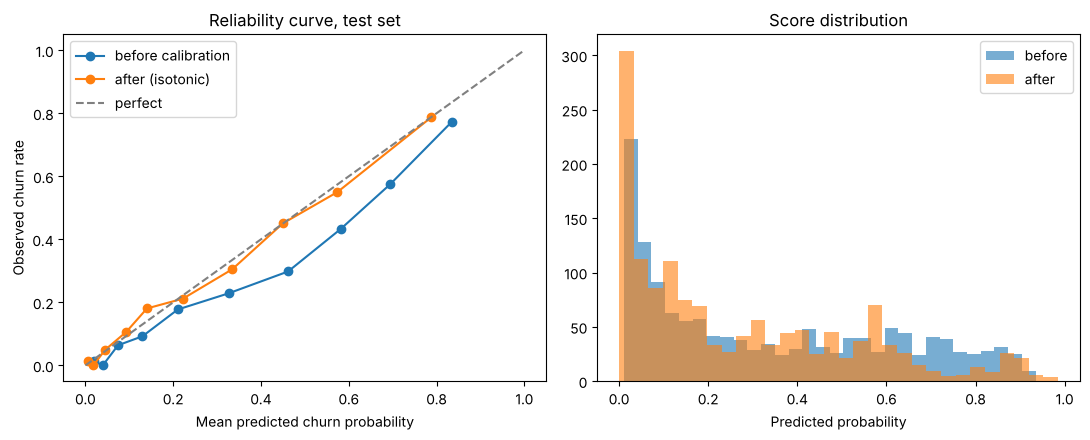

In [10]:
# Reliability curve and Brier score (point 1).
def ece(yv, p, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1)); edges[-1] += 1e-9
    b = np.digitize(p, edges[1:-1]); return float(sum(abs(p[b == k].mean() - yv[b == k].mean()) * (b == k).mean() for k in np.unique(b)))
cal_stats = {'brier_uncalibrated': brier_score_loss(yt, p_raw_test), 'brier_calibrated': brier_score_loss(yt, p_test),
             'brier_baseline_rate_only': brier_score_loss(yt, np.full(len(yt), y_train.mean())),
             'ece_uncalibrated': ece(yt, p_raw_test), 'ece_calibrated': ece(yt, p_test),
             'mean_score_uncalibrated': float(p_raw_test.mean()), 'mean_score_calibrated': float(p_test.mean()), 'observed_churn_rate_test': float(yt.mean())}
print(pd.Series(cal_stats).round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for p, lab in [(p_raw_test, 'before calibration'), (p_test, 'after (%s)' % CAL_METHOD)]:
    fr, mp = calibration_curve(yt, p, n_bins=10, strategy='quantile'); ax[0].plot(mp, fr, marker='o', label=lab)
ax[0].plot([0, 1], [0, 1], '--', color='gray', label='perfect'); ax[0].set(xlabel='Mean predicted churn probability', ylabel='Observed churn rate', title='Reliability curve, test set'); ax[0].legend()
ax[1].hist(p_raw_test, bins=30, alpha=.6, label='before'); ax[1].hist(p_test, bins=30, alpha=.6, label='after'); ax[1].set(xlabel='Predicted probability', title='Score distribution'); ax[1].legend()
plt.tight_layout(); plt.show()

In [11]:
# Point 6: subgroup behaviour on the test set at the saved threshold. 'gender' is audited even if it is no longer a model input.
flag = (p_test >= threshold).astype(int)
audit = X_test[['gender', 'SeniorCitizen', 'Partner', 'Dependents']].copy(); audit['y'] = yt; audit['flag'] = flag
rows = []
for col in ['gender', 'SeniorCitizen', 'Partner', 'Dependents']:
    for val, g in audit.groupby(col):
        rows.append({'attribute': col, 'group': str(val), 'n': len(g), 'churn_rate': g['y'].mean(), 'flag_rate': g['flag'].mean(),
                     'recall': recall_score(g['y'], g['flag']), 'precision': precision_score(g['y'], g['flag'], zero_division=0)})
sub = pd.DataFrame(rows); display(sub.round(3))
print('Largest recall gap within an attribute: %.3f | largest flag-rate gap: %.3f' % (
      max(sub[sub.attribute == a].recall.max() - sub[sub.attribute == a].recall.min() for a in sub.attribute.unique()),
      max(sub[sub.attribute == a].flag_rate.max() - sub[sub.attribute == a].flag_rate.min() for a in sub.attribute.unique())))
print('Differences in flag rate partly reflect real differences in churn rate; recall and precision gaps are the ones to investigate. Groups are small, see n.')

,attribute,group,n,churn_rate,flag_rate,recall,precision
0,gender,Female,687,0.281,0.349,0.715,0.575
1,gender,Male,722,0.251,0.335,0.746,0.558
2,SeniorCitizen,0,1187,0.233,0.296,0.692,0.544
3,SeniorCitizen,1,222,0.441,0.590,0.837,0.626
4,Partner,No,736,0.337,0.457,0.798,0.589
5,Partner,Yes,673,0.187,0.217,0.595,0.514
6,Dependents,No,978,0.310,0.420,0.779,0.574
7,Dependents,Yes,431,0.165,0.165,0.521,0.521


Largest recall gap within an attribute: 0.258 | largest flag-rate gap: 0.294
Differences in flag rate partly reflect real differences in churn rate; recall and precision gaps are the ones to investigate. Groups are small, see n.


In [12]:
%%writefile churn_serving.py
# churn_serving.py - input validation, scoring and explanations for the saved churn model.
import json
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

NON_NEGATIVE = {'tenure', 'MonthlyCharges', 'TotalCharges'}
BINARY = {'SeniorCitizen'}


def installed_versions():
    import sklearn, xgboost, lightgbm, shap, scipy
    return {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__,
            'lightgbm': lightgbm.__version__, 'shap': shap.__version__, 'pandas': pd.__version__,
            'numpy': np.__version__, 'scipy': scipy.__version__, 'joblib': joblib.__version__}


def check_versions(meta, strict=False):
    """Compare library versions recorded at training time with the ones installed now."""
    now, then = installed_versions(), meta.get('versions', {})
    diffs = {k: (then[k], now.get(k)) for k in then if k != 'python' and then[k] != now.get(k)}
    if diffs:
        msg = 'Library versions differ from training time (saved, installed): %s. joblib files may not load or may score differently.' % diffs
        if strict:
            raise RuntimeError(msg)
        warnings.warn(msg)
    return diffs


def load_bundle(directory='.', strict_versions=False):
    d = Path(directory)
    meta = json.loads((d / 'churn_model_meta.json').read_text())
    check_versions(meta, strict=strict_versions)
    return {'meta': meta, 'model': joblib.load(d / 'churn_model.joblib'),
            'explainer_pipeline': joblib.load(d / 'churn_xgb_explainer.joblib')}


def prepare(df, meta):
    """Validate a frame of raw customers and return exactly the columns the model expects. Raises ValueError listing every problem."""
    if not isinstance(df, pd.DataFrame):
        raise TypeError('Expected a pandas DataFrame, got %s' % type(df).__name__)
    if len(df) == 0:
        raise ValueError('No rows to score')
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    need = meta['input_columns']
    missing = [c for c in need if c not in df.columns]
    if missing:
        raise ValueError('Missing required columns: %s' % missing)
    extra = [c for c in df.columns if c not in need]
    if extra:
        warnings.warn('Ignoring columns the model does not use: %s' % extra)
    df = df[need]
    problems, out = [], pd.DataFrame(index=df.index)
    for c in meta['numeric_columns']:
        s = df[c]
        if not pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
            s = s.astype('string').str.strip().replace('', pd.NA)       # whitespace-only strings become missing
        num = pd.to_numeric(s, errors='coerce').astype(float)
        if c == 'TotalCharges' and 'tenure' in df.columns:
            ten = pd.to_numeric(df['tenure'], errors='coerce')
            num = num.where(~(num.isna() & (ten == 0)), 0.0)            # a brand-new customer has been billed nothing
        bad = num.isna()
        if bad.any():
            problems.append('%s: %d missing or non-numeric value(s), first at index %r' % (c, int(bad.sum()), bad.idxmax()))
        if c in NON_NEGATIVE and (num < 0).any():
            problems.append('%s: negative values' % c)
        if c in BINARY and (~num.isin([0, 1]) & num.notna()).any():
            problems.append('%s: must be 0 or 1' % c)
        out[c] = num
    for c in meta['categorical_columns']:
        s = df[c]
        if s.isna().any():
            problems.append('%s: %d missing value(s)' % (c, int(s.isna().sum())))
        elif not all(isinstance(v, str) for v in s):
            problems.append('%s: expected text values, got other types' % c)
        else:
            s = s.str.strip()
            unseen = sorted(set(s) - set(meta['categorical_levels'][c]))
            if unseen:
                warnings.warn('%s: unseen categories %s are encoded as all zeros' % (c, unseen))
        out[c] = s
    if problems:
        raise ValueError('Invalid input: ' + '; '.join(problems))
    return out[need]


def predict(df, bundle):
    """Calibrated churn probability and a flag at the saved threshold."""
    meta = bundle['meta']
    p = bundle['model'].predict_proba(prepare(df, meta))[:, 1]
    return pd.DataFrame({'churn_probability': p, 'flagged': p >= meta['threshold'],
                         'threshold': meta['threshold'], 'threshold_source': meta['threshold_source']}, index=df.index)


def _raw_name(feature, columns):
    body = feature.split('__', 1)[1]
    if feature.startswith('cat__'):
        hits = [c for c in columns if body.startswith(c + '_')]
        return max(hits, key=len)
    return body


def explain(df, bundle, top_k=5):
    """Per-customer SHAP contributions (log-odds of the XGBoost score), summed back to the raw input columns.
    Returns (contributions DataFrame, base value, margin Series). Contributions + base value = margin."""
    import shap
    meta = bundle['meta']
    X = prepare(df, meta)
    pipe = bundle['explainer_pipeline']
    prep, model = pipe.named_steps['prep'], pipe.named_steps['model']
    Xt = prep.transform(X)
    Xt = Xt.toarray() if hasattr(Xt, 'toarray') else np.asarray(Xt)
    ex = shap.TreeExplainer(model)
    sv = ex.shap_values(Xt)
    names = prep.get_feature_names_out()
    raw = [_raw_name(n, meta['input_columns']) for n in names]
    contrib = pd.DataFrame(sv, columns=names, index=X.index).T.groupby(raw).sum().T
    margin = pd.Series(model.predict(Xt, output_margin=True), index=X.index)
    return contrib, float(np.ravel(ex.expected_value)[0]), margin


def top_reasons(df, bundle, k=3):
    """Plain-language reasons per customer: the k raw columns pushing risk up most, with their values."""
    contrib, base, margin = explain(df, bundle)
    X = prepare(df, bundle['meta'])
    rows = []
    for i in contrib.index:
        top = contrib.loc[i].sort_values(ascending=False).head(k)
        rows.append([{'feature': f, 'value': X.loc[i, f], 'log_odds_push': round(float(v), 3)} for f, v in top.items() if v > 0])
    return pd.Series(rows, index=contrib.index)


Writing churn_serving.py


In [13]:
import churn_serving as cs, importlib; importlib.reload(cs)
explainer_pipe = searches['xgboost'].best_estimator_          # XGBoost pipeline used for SHAP
pre = explainer_pipe.named_steps['prep']
meta = {
    'selected_model': best_name, 'calibration_method': CAL_METHOD, 'seed': SEED,
    'threshold': threshold, 'threshold_source': threshold_source, 'threshold_note': threshold_note,
    'input_columns': X_train_f.columns.tolist(), 'dropped_columns': DROP, 'feature_set_chosen': chosen, 'totalcharges_mode': TC_MODE,
    'numeric_columns': [c for c in X_train_f.columns if c in X_train_f.select_dtypes(include='number').columns],
    'categorical_columns': X_train_f.select_dtypes(exclude='number').columns.tolist(),
    'categorical_levels': {c: sorted(X_train_f[c].unique().tolist()) for c in X_train_f.select_dtypes(exclude='number').columns},
    'explainer_model': 'xgboost', 'explainer_matches_served_model': best_name == 'xgboost',
    'versions': cs.installed_versions(),
    'test_metrics': {k: float(v) for k, v in pt.items()}, 'test_metrics_ci95': ci, 'bootstrap_resamples': B,
    'test_auc_baseline_contract_tenure': float(roc_auc_score(yt, p_base)),
    'calibration_test': cal_stats, 'ablation_mean_auc': abl['mean_auc'].to_dict(),
    'nested_cv_auc': {k: {'mean': float(v.mean()), 'sd': float(v.std(ddof=1))} for k, v in nested.items()},
    'repeated_cv_auc': {k: {'mean': float(v.mean()), 'sd': float(v.std(ddof=1))} for k, v in rep.items()},
    'subgroups': sub.to_dict(orient='records'),
}
joblib.dump(cal_model, 'churn_model.joblib')
joblib.dump(explainer_pipe, 'churn_xgb_explainer.joblib')
Path('churn_model_meta.json').write_text(json.dumps(meta, indent=2, default=float))
print('saved; versions:', meta['versions'])

saved; versions: {'python': '3.13.16', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'shap': '0.53.0', 'pandas': '3.0.5', 'numpy': '2.5.3', 'scipy': '1.18.1', 'joblib': '1.6.0'}


In [14]:
# Serving checks (point 7): the saved bundle must reproduce results and reject bad rows.
bundle = cs.load_bundle('.')
out = cs.predict(X_test, bundle)                                   # raw test frame incl. unused columns -> ignored with a warning
assert np.allclose(out['churn_probability'].values, p_test, atol=1e-12)

def must_fail(frame, label):
    try: cs.prepare(frame, bundle['meta'])
    except ValueError as e: print('rejected [%s]: %s' % (label, str(e)[:110])); return
    raise AssertionError('accepted bad input: ' + label)
row = X_test.iloc[:3].copy()
must_fail(row.drop(columns=['Contract']), 'missing column')
bad = row.copy(); bad['tenure'] = ['abc', 5, 7]; must_fail(bad, 'text in numeric column')
bad = row.copy(); bad['MonthlyCharges'] = [-1.0, 50, 60]; must_fail(bad, 'negative charge')
bad = row.copy(); bad['SeniorCitizen'] = [2, 0, 1]; must_fail(bad, 'SeniorCitizen not 0/1')
bad = row.copy(); bad['Contract'] = [None, 'Two year', 'One year']; must_fail(bad, 'missing category')
bad = row.copy(); bad['InternetService'] = [1, 2, 3]; must_fail(bad, 'number in text column')
unseen = row.copy(); unseen['PaymentMethod'] = 'Crypto'
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always'); assert np.isfinite(cs.predict(unseen, bundle)['churn_probability']).all()
    msgs = [str(x.message) for x in w if 'unseen' in str(x.message)]; assert msgs, 'no unseen-category warning'; print('unseen category -> warning only:', msgs[0][:80])

# If TotalCharges is an input (not in the chosen set), whitespace strings must be handled. Test the rule on a copy of the meta.
m2 = json.loads(json.dumps(bundle['meta'])); m2['input_columns'] = X.columns.tolist(); m2['numeric_columns'] = [c for c in X.columns if c in X.select_dtypes(include='number').columns]
m2['categorical_columns'] = X.select_dtypes(exclude='number').columns.tolist(); m2['categorical_levels'] = {c: sorted(X[c].unique().tolist()) for c in m2['categorical_columns']}
t = X_test.iloc[:2].copy(); t['TotalCharges'] = [' ', '  12.5 ']; t['tenure'] = [0, 3]
r = cs.prepare(t, m2); assert r['TotalCharges'].tolist() == [0.0, 12.5], r['TotalCharges'].tolist()
t['TotalCharges'] = [' ', ' ']; t['tenure'] = [4, 3]
try: cs.prepare(t, m2); raise AssertionError('blank TotalCharges with tenure>0 accepted')
except ValueError: print('blank TotalCharges for a customer with tenure > 0 is rejected; for tenure 0 it becomes 0')
print('version check against saved meta:', cs.check_versions(bundle['meta']) or 'identical')

rejected [missing column]: Missing required columns: ['Contract']
rejected [text in numeric column]: Invalid input: tenure: 1 missing or non-numeric value(s), first at index np.int64(437)
rejected [negative charge]: Invalid input: MonthlyCharges: negative values
rejected [SeniorCitizen not 0/1]: Invalid input: SeniorCitizen: must be 0 or 1
rejected [missing category]: Invalid input: Contract: 1 missing value(s)
rejected [number in text column]: Invalid input: InternetService: expected text values, got other types
unseen category -> warning only: PaymentMethod: unseen categories ['Crypto'] are encoded as all zeros
blank TotalCharges for a customer with tenure > 0 is rejected; for tenure 0 it becomes 0
version check against saved meta: identical


In [15]:
# Point 8: SHAP for individual predictions, summed back to the raw columns, with an additivity test.
sample = X_test.iloc[:300]
contrib, base_value, margin = cs.explain(sample, bundle)
err = (contrib.sum(axis=1) + base_value - margin).abs().max()
print('max |sum(SHAP) + base - model margin| over 300 customers = %.2e' % err); assert err < 1e-4
assert set(contrib.columns) <= set(bundle['meta']['input_columns']), set(contrib.columns) - set(bundle['meta']['input_columns'])
print('raw columns explained:', len(contrib.columns), 'of', len(bundle['meta']['input_columns']))
print('mean |SHAP| by raw column (global view):'); print(contrib.abs().mean().sort_values(ascending=False).head(8).round(3).to_string())
pr = cs.predict(sample.iloc[:3], bundle); rs = cs.top_reasons(sample.iloc[:3], bundle, k=3)
for i in sample.index[:3]:
    print('customer %s: calibrated risk %.1f%%, flagged=%s, reasons: %s' % (i, 100 * pr.loc[i, 'churn_probability'], bool(pr.loc[i, 'flagged']),
          '; '.join('%s=%s (+%.2f)' % (d['feature'], d['value'], d['log_odds_push']) for d in rs[i]) or 'none pushing risk up'))
print('Note: SHAP values are in log-odds of the uncalibrated XGBoost score; the displayed probability is the calibrated one.')

max |sum(SHAP) + base - model margin| over 300 customers = 1.67e-06
raw columns explained: 17 of 17
mean |SHAP| by raw column (global view):
Contract            0.642
tenure              0.587
InternetService     0.305
OnlineSecurity      0.228
MonthlyCharges      0.207
TechSupport         0.175
PaymentMethod       0.168
PaperlessBilling    0.131
customer 437: calibrated risk 2.9%, flagged=False, reasons: MonthlyCharges=114.05 (+0.61); InternetService=Fiber optic (+0.19); MultipleLines=Yes (+0.07)
customer 2280: calibrated risk 67.4%, flagged=True, reasons: Contract=Month-to-month (+0.46); MonthlyCharges=100.15 (+0.40); tenure=8.0 (+0.35)
customer 2235: calibrated risk 7.3%, flagged=False, reasons: TechSupport=No (+0.13); MultipleLines=Yes (+0.09); PaperlessBilling=Yes (+0.09)
Note: SHAP values are in log-odds of the uncalibrated XGBoost score; the displayed probability is the calibrated one.
